# 19 · Certified and budgeted inference: answers you can trust when exact VE is too expensive

Exact variable elimination (VE) gives the exact posterior, but its time and
memory grow exponentially with the width of the network.  On a dense network
you soon have to choose: refuse the query, or sample and hope.  NBN has four
opt-in ways to do better, all on the same fitted network:

* **certified sampling** (`certified_query`): likelihood weighting that returns
  an interval for every class, and all intervals hold *together* with
  probability at least `1 - delta`;
* **anytime certified sampling**: stop on a time budget or a target width, and
  the interval is still valid;
* **conditioning** (`TensorVariableElimination(on_oom="condition")`,
  `conditioned_query`): the *exact* answer when VE does not fit in memory,
  paid for in time;
* **bounded conditioning** (`conditioned_query(..., enumerate_limit=k)`):
  bounds that hold with probability 1 and close on the exact answer as more
  work is done.

The router (`HybridRouter(fallback=...)`) uses them automatically, and
`query_many` runs independent queries in parallel.

Ground truth: a random discrete network with 24 variables, 3 values each, and
dense connections (each variable may depend on any of the 10 before it, with
probability 0.7, so up to 10 parents).  Data are drawn from random
conditional tables and NBN fits the tables (`CategoricalTableMechanism`).
All guarantees below are about **the fitted model's posterior**: the
*inference* error, not the learning error (for learning error see
`credal_query` / `pac_query`).  The network is small enough that exact VE still
answers (about 2 MB), so every answer can be checked against the exact one;
section 3 then pretends that memory is short.

- **NBN API:** `nbn.inference.certified_query`, `CertifiedEngine`, `conditioned_query`, `query_many`; `TensorVariableElimination(memory_budget=..., on_oom="condition")`; `HybridRouter(fallback="certified" | "condition")`.
- **Runtime:** under 20 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"`, then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

In [1]:
import logging
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

from nbn import (
    CategoricalTableMechanism,
    HybridRouter,
    LikelihoodWeightingEngine,
    NeuralBayesianNetwork,
    TensorVariableElimination,
    seed_all,
)
from nbn.inference import certified_query, conditioned_query, query_many
from nbn.inference._memory import OutOfMemoryError
from nbn.inference.conditioning import ConditioningLimitError
from nbn.utils.device import resolve_device
from _figures import BLUE, ORANGE, AQUA, VERMILLION, GREY, INK, DOUBLE, SINGLE, save, use_style

use_style()  # one style for every example: palette, sizes, fonts (_figures.py)

# "auto" picks CUDA, then Apple MPS, then the CPU.  The stored outputs were made
# with NBN_EXAMPLES_DEVICE=cpu; on an accelerator the last digits can differ.
device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)

K, N_NODES, WINDOW, P_EDGE = 3, 24, 10, 0.7
gen = torch.Generator().manual_seed(0)
NAMES = [f"X{i}" for i in range(N_NODES)]
EDGES = [(NAMES[i], NAMES[j]) for j in range(1, N_NODES) for i in range(max(0, j - WINDOW), j)
         if torch.rand((), generator=gen) < P_EDGE]
PARENTS = {v: [a for a, b in EDGES if b == v] for v in NAMES}
TRUE_CPT = {v: torch.softmax(1.5 * torch.randn(K ** len(PARENTS[v]), K, generator=gen), -1)
            for v in NAMES}


def simulate(n: int, seed: int) -> dict:
    """Ancestral sampling from the true tables (parents' values index the row)."""
    g = torch.Generator().manual_seed(seed)
    x = {}
    for v in NAMES:
        row = torch.zeros(n, dtype=torch.long)
        for p in PARENTS[v]:
            row = row * K + x[p]
        x[v] = torch.multinomial(TRUE_CPT[v][row], 1, generator=g).squeeze(1)
    return x


model = NeuralBayesianNetwork(EDGES, dict.fromkeys(NAMES, ("discrete", K)), device=device)
for v in NAMES:
    model.set_mechanism(v, CategoricalTableMechanism())
model.fit({k: v.to(device) for k, v in simulate(20_000, seed=1).items()})

ve = TensorVariableElimination()
print(f"{len(EDGES)} edges, at most {max(map(len, PARENTS.values()))} parents per node")

device: cpu
136 edges, at most 9 parents per node


## 1. Certified sampling: an interval that holds, not just a point estimate

Plain likelihood weighting (LW) returns a point estimate and, at best, an
effective sample size, which is a heuristic.  `certified_query` runs
unnormalised LW with a fixed number of samples `M` and returns, for every class
`y`, an interval `[lower_y, upper_y]`.  With probability at least `1 - delta`
**all** intervals contain `P(y | e)` at once.  The proof needs every weight to
be bounded, so the evidence must be on discrete nodes with discrete parents (checked, not
assumed).

We draw 40 random queries: one target and three observed variables each.

In [2]:
qgen = torch.Generator().manual_seed(7)
QUERIES = []
for _ in range(40):
    perm = torch.randperm(N_NODES, generator=qgen).tolist()
    evidence = {NAMES[j]: int(torch.randint(0, K, (), generator=qgen)) for j in perm[1:4]}
    QUERIES.append((NAMES[perm[0]], evidence))

exact = [model.query([t], evidence=e, engine=ve).cpu().double() for t, e in QUERIES]

seed_all(0)
lw = LikelihoodWeightingEngine(n_samples=50_000)
point = [model.query([t], evidence=e, engine=lw).cpu().double() for t, e in QUERIES]
start = time.perf_counter()
cert = [certified_query(model, t, e, n_samples=50_000, delta=0.05) for t, e in QUERIES]
seconds = time.perf_counter() - start

covered = sum(bool(((x >= a.lower - 1e-12) & (x <= a.upper + 1e-12)).all()) for x, a in zip(exact, cert))
lw_err = max(float((p - x).abs().max()) for p, x in zip(point, exact))
widths = torch.tensor([a.max_width for a in cert])
print(f"certified, 95%: all classes inside in {covered}/{len(QUERIES)} queries "
      f"({seconds:.2f} s for {len(QUERIES)} queries)")
print(f"widest class per query: median {float(widths.median()):.3f}, max {float(widths.max()):.3f}")
print(f"plain LW, same M: largest error {lw_err:.3f}, and nothing tells you how large it may be")

certified, 95%: all classes inside in 40/40 queries (1.13 s for 40 queries)
widest class per query: median 0.098, max 0.148
plain LW, same M: largest error 0.015, and nothing tells you how large it may be


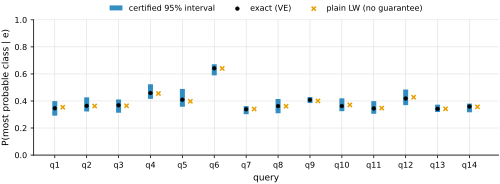

In [3]:
SHOW = 14
fig, ax = plt.subplots(figsize=(DOUBLE, 2.6))
for i, (x, a, p) in enumerate(zip(exact[:SHOW], cert[:SHOW], point[:SHOW])):
    y = int(x.argmax())                      # the most probable class of each query
    ax.vlines(i, float(a.lower[y]), float(a.upper[y]), color=BLUE, lw=5, alpha=0.8,
              label="certified 95% interval" if i == 0 else None)
    ax.scatter(i, float(x[y]), color=INK, s=14, zorder=3, label="exact (VE)" if i == 0 else None)
    ax.scatter(i + 0.25, float(p[y]), color=ORANGE, marker="x", s=18, zorder=3,
               label="plain LW (no guarantee)" if i == 0 else None)
ax.set(xticks=range(SHOW), xticklabels=[f"q{i + 1}" for i in range(SHOW)],
       ylabel="P(most probable class | e)", ylim=(0, 1), xlabel="query")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
save(fig, "19_certified_intervals")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** For the first 14 queries, the posterior of the most probable class:
the certified 95% interval from `certified_query` (blue bar, `M = 50 000`
samples), the exact value from VE (black dot) and plain likelihood weighting
with the same number of samples (orange cross).  The 95% promise covers all
three classes of a query at once.

The interval is wide when the evidence is unlikely: the sample size needed
grows like `W / P(e)`, where `W` bounds the weights (`a.weight_bound`).  The
certificate makes that cost visible instead of hiding it.

## 2. More samples, narrower intervals; stop whenever you like

With `M` fixed in advance the width shrinks like `1 / sqrt(M)`.  Choosing `M`
by looking at the data ("sample until it is narrow enough") would break a
fixed-`M` certificate.  The **anytime** mode (`time_budget_s=` or
`target_width=`) checks the interval at doubling sample sizes and spends
`delta / (j (j + 1))` at checkpoint `j`; these add up to `delta`, so the reported
interval is valid whatever the stopping rule.

In [4]:
target, evidence = QUERIES[1]
truth = exact[1]
M_GRID = [1_000, 4_000, 16_000, 64_000, 256_000]
fixed = [certified_query(model, target, evidence, n_samples=m) for m in M_GRID]
budgets = [0.05, 0.2, 0.8]
anytime = [certified_query(model, target, evidence, time_budget_s=b) for b in budgets]
by_width = certified_query(model, target, evidence, target_width=0.02)

print(f"{'samples M':>10s} {'width':>8s}  inside")
for m, a in zip(M_GRID, fixed):
    print(f"{m:10d} {a.max_width:8.4f}  {bool(((truth >= a.lower) & (truth <= a.upper)).all())}")
for b, a in zip(budgets, anytime):
    print(f"time budget {b:4.2f} s: {a.n_samples:8d} samples, {a.n_checkpoints} checkpoints, "
          f"width {a.max_width:.4f}, inside {bool(((truth >= a.lower) & (truth <= a.upper)).all())}")
print(f"target width 0.02: stopped at {by_width.n_samples} samples, width {by_width.max_width:.4f}")

plain = certified_query(model, target, evidence, n_samples=200_000)
collapsed = certified_query(model, target, evidence, n_samples=200_000, collapse="auto")
print(f'200 000 samples: plain width {plain.max_width:.4f}; collapse="auto" width {collapsed.max_width:.1e} '
      f"(sampled cutset: {list(collapsed.collapsed) or 'none'})")

 samples M    width  inside
      1000   0.8116  True
      4000   0.5582  True
     16000   0.2199  True
     64000   0.0891  True
    256000   0.0394  True
time budget 0.05 s:   131072 samples, 6 checkpoints, width 0.0756, inside True
time budget 0.20 s:   524288 samples, 8 checkpoints, width 0.0349, inside True
time budget 0.80 s:  2097152 samples, 10 checkpoints, width 0.0168, inside True
target width 0.02: stopped at 2097152 samples, width 0.0169
200 000 samples: plain width 0.0451; collapse="auto" width 3.3e-04 (sampled cutset: none)


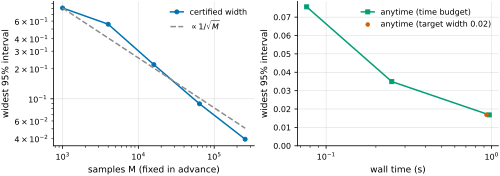

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(DOUBLE, 2.5))
w = np.array([a.max_width for a in fixed])
axes[0].loglog(M_GRID, w, "o-", color=BLUE, label="certified width")
axes[0].loglog(M_GRID, w[0] * np.sqrt(M_GRID[0] / np.array(M_GRID)), "--", color=GREY,
               label=r"$\propto 1/\sqrt{M}$")
axes[0].set(xlabel="samples M (fixed in advance)", ylabel="widest 95% interval")
axes[0].legend()
axes[1].semilogx([a.seconds for a in anytime], [a.max_width for a in anytime], "s-", color=AQUA,
                 label="anytime (time budget)")
axes[1].scatter([by_width.seconds], [by_width.max_width], color=VERMILLION, zorder=3,
                label="anytime (target width 0.02)")
axes[1].set(xlabel="wall time (s)", ylabel="widest 95% interval", ylim=(0, None))
axes[1].legend()
save(fig, "19_width_vs_budget")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** Left: the widest of the three certified 95% intervals of one query
against the number of samples fixed in advance (blue), with a `1/sqrt(M)` guide
(grey, dashed).  Right: the anytime mode, stopped by a time budget (green
squares) or by a target width of 0.02 (red dot); the x-axis is the measured
wall time.  Every interval in the table above contains the exact answer.

`collapse="auto"` (collapsed, or cutset, sampling) samples only a small set of
variables and computes the rest exactly; `.collapsed` lists the sampled
variables.  Here the whole query fits in memory, so nothing is sampled: the
answer is exact, and the small width left is a rigorous bound on float32
rounding, not sampling error.  On dense networks where most of the query must be
sampled it pays off mainly on GPUs, so it is off by default.

## 3. Memory is short: the exact answer by conditioning

`TensorVariableElimination(memory_budget=...)` refuses a query whose
elimination would not fit (`OutOfMemoryError`), instead of crashing.  With
`on_oom="condition"` it **clamps** a small set of variables `C` (a cutset),
runs VE once per assignment of `C` on the smaller problem, and adds the
results.  This is exact, and costs time instead of memory: `3^|C|` runs, done as
rows of one batched elimination.  `conditioned_query` gives the same answer
together with the cutset it used.

In [6]:
target, evidence = "X2", {"X23": 1, "X12": 0}
truth = model.query([target], evidence=evidence, engine=ve).cpu().double()
peak = ve.estimate_peak_bytes(model, target, evidence)
print(f"exact VE needs about {peak / 2**20:.2f} MiB for P({target} | X23, X12)")

FRACTIONS = [2.0, 0.3, 0.1, 0.03, 0.01]
rows = []
for frac in FRACTIONS:
    budget = peak * frac
    try:
        model.query([target], evidence=evidence, engine=TensorVariableElimination(memory_budget=budget))
        plain = "answers"
    except OutOfMemoryError:
        plain = "refused"
    start = time.perf_counter()
    try:
        info = conditioned_query(model, target, evidence, memory_budget=budget)
    except ConditioningLimitError as exc:       # e.g. below the MPS allocator's block size
        print(f"budget {frac:.2f} x peak: {exc}")
        continue
    sec = time.perf_counter() - start
    err = float((info.estimate.cpu().double() - truth).abs().max())
    rows.append((frac, plain, len(info.cutset), info.n_instantiations, sec, err))

print(f"{'budget / VE peak':>17s} {'plain VE':>9s} {'|C|':>4s} {'runs':>6s} {'time (s)':>9s} {'|error|':>9s}")
for frac, plain, c, n, sec, err in rows:
    print(f"{frac:17.2f} {plain:>9s} {c:4d} {n:6d} {sec:9.3f} {err:9.1e}")

# The same thing inside the engine: on_oom="condition" instead of a refusal.
# a budget of about 3% of the peak (the feasible one closest to it on this device)
MID = min((r[0] for r in rows), key=lambda f: abs(np.log(f / 0.03)))
engine = TensorVariableElimination(memory_budget=MID * peak, on_oom="condition")
answer = model.query([target], evidence=evidence, engine=engine).cpu().double()
print(f'\nTensorVariableElimination(on_oom="condition") at {MID:.0%} of the peak: '
      f"|error| {float((answer - truth).abs().max()):.1e}")

exact VE needs about 1.99 MiB for P(X2 | X23, X12)


 budget / VE peak  plain VE  |C|   runs  time (s)   |error|
             2.00   answers    0      1     0.008   3.0e-08
             0.30   refused    2      9     0.018   6.7e-08
             0.10   refused    4     81     0.055   6.1e-08
             0.03   refused    6    729     0.273   6.9e-08
             0.01   refused    8   6561     1.758   6.0e-08



TensorVariableElimination(on_oom="condition") at 3% of the peak: |error| 7.5e-08


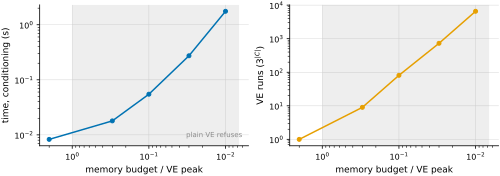

In [7]:
frac = np.array([r[0] for r in rows])
fig, axes = plt.subplots(1, 2, figsize=(DOUBLE, 2.5))
axes[0].loglog(frac, [r[4] for r in rows], "o-", color=BLUE)
axes[0].set(xlabel="memory budget / VE peak", ylabel="time, conditioning (s)")
axes[1].loglog(frac, [r[3] for r in rows], "o-", color=ORANGE)
axes[1].set(xlabel="memory budget / VE peak", ylabel=r"VE runs ($3^{|C|}$)")
for ax in axes:
    ax.axvspan(frac.min() / 1.5, 1.0, color=GREY, alpha=0.15, lw=0)
    ax.invert_xaxis()
axes[0].text(0.97, 0.05, "plain VE refuses", transform=axes[0].transAxes, ha="right", va="bottom",
             fontsize=7, color=GREY)
save(fig, "19_conditioning_trade")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** One query answered exactly under a shrinking memory budget (x-axis,
as a fraction of the memory exact VE needs; it decreases to the right).  Left:
wall time of `conditioned_query` (the computation `on_oom="condition"` runs).  Right: the number
of VE runs, `3^|C|` for a cutset `C`.  In the grey region plain VE refuses the
query; conditioning still returns the exact answer (the `|error|` column above
is rounding error).  On Apple MPS the allocator hands out memory in large
blocks, so the smallest budgets cannot be met there and are reported as such.  Memory turns into time at an exponential rate; on dense
graphs this sets a hard limit, after which only sampling answers.

## 4. Bounded conditioning: bounds that hold with probability 1

If enumerating every assignment of `C` takes too long, stop early
(`enumerate_limit=k` or `time_budget_s=`).  The assignments already done give
part of the answer, and the mass not yet seen is bounded, so
`lower <= P(y | e) <= upper` holds **with certainty**, not with a probability.
The bounds close on the exact answer as more assignments are enumerated.

In [8]:
target, evidence = "X2", {"X23": 1}
truth = model.query([target], evidence=evidence, engine=ve).cpu().double()
budget = MID * ve.estimate_peak_bytes(model, target, evidence)
LIMITS = [4, 16, 64, 256, 1024, 2048, None]
bounds = [conditioned_query(model, target, evidence, memory_budget=budget,
                            enumerate_limit=k if k is not None else 10**9) for k in LIMITS]
print(f"cutset of {len(bounds[0].cutset)} variables: {bounds[0].n_instantiations} assignments")
for b in bounds:
    # 1e-6: the last, exact step equals VE up to float32 rounding
    sound = bool(((truth >= b.lower.cpu() - 1e-6) & (truth <= b.upper.cpu() + 1e-6)).all())
    print(f"enumerated {b.n_enumerated:5d}: widest interval {b.max_width:.3f}, exact={b.exact}, "
          f"contains the truth: {sound}")

cutset of 7 variables: 2187 assignments
enumerated     4: widest interval 0.995, exact=False, contains the truth: True
enumerated    16: widest interval 0.987, exact=False, contains the truth: True
enumerated    64: widest interval 0.962, exact=False, contains the truth: True
enumerated   256: widest interval 0.888, exact=False, contains the truth: True
enumerated  1024: widest interval 0.593, exact=False, contains the truth: True
enumerated  2048: widest interval 0.073, exact=False, contains the truth: True
enumerated  2187: widest interval 0.000, exact=True, contains the truth: True


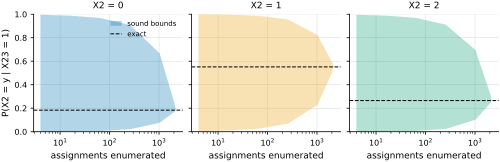

In [9]:
fig, axes = plt.subplots(1, K, figsize=(DOUBLE, 2.3), sharey=True)
n_done = [b.n_enumerated for b in bounds]
for y, (ax, color) in enumerate(zip(axes, (BLUE, ORANGE, AQUA))):
    ax.fill_between(n_done, [float(b.lower[y]) for b in bounds], [float(b.upper[y]) for b in bounds],
                    color=color, alpha=0.3, lw=0, label="sound bounds")
    ax.axhline(float(truth[y]), color=INK, lw=1, ls="--", label="exact")
    ax.set(xscale="log", xlabel="assignments enumerated", title=f"{target} = {y}", ylim=(0, 1))
axes[0].set_ylabel(f"P({target} = y | X23 = 1)")
axes[0].legend(loc="upper right", fontsize=7)
save(fig, "19_bounded_conditioning")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** Bounded conditioning on `P(X2 = y | X23 = 1)`, one panel per class
`y`: the band between the lower and upper bound (shaded) against the number of
assignments of the cutset enumerated so far, and the exact value (dashed).
The bands always contain the exact values and collapse onto them when every
assignment is done.

Honest limit: the unseen mass must be smaller than `P(e)` before the bounds
become informative.  With several unlikely observations, `P(e)` is tiny and the
bounds stay close to `[0, 1]` until almost every assignment is enumerated;
certified sampling (section 1) is then the better tool.

## 5. Let the router choose, and run many queries at once

`HybridRouter` answers with exact VE when the plan fits the memory budget.
When it does not, `fallback=` decides: plain LW (`"lw"`, the default, no
guarantee), certified LW (`"certified"`) or conditioning (`"condition"`, exact,
falls back to LW if the cutset would be too large).  `last_certificate` holds
the interval when the certified engine answered the last query, and is `None`
otherwise.

In [10]:
target, evidence = "X2", {"X23": 1, "X12": 0}
truth = model.query([target], evidence=evidence, engine=ve).cpu().double()
peak = ve.estimate_peak_bytes(model, target, evidence)
seed_all(0)
logging.getLogger("nbn.inference.hybrid").setLevel(logging.ERROR)   # silence "VE does not fit" notes
for fallback in ("lw", "certified", "condition"):
    router = HybridRouter(fallback=fallback, memory_budget=0.1 * peak)
    p = model.query([target], evidence=evidence, engine=router).cpu().double()
    cert_ = router.last_certificate
    note = "no certificate" if cert_ is None else (
        f"certified: every class within [{', '.join(f'{lo:.3f}-{hi:.3f}' for lo, hi in zip(cert_.lower.tolist(), cert_.upper.tolist()))}]")
    print(f"fallback={fallback:10s} answered by {router.last_engine:20s} "
          f"|error| {float((p - truth).abs().max()):.1e}   {note}")

fallback=lw         answered by likelihood_weighting |error| 2.2e-02   no certificate
fallback=certified  answered by certified            |error| 2.5e-03   certified: every class within [0.198-0.218, 0.540-0.577, 0.224-0.244]
fallback=condition  answered by conditioning         |error| 6.0e-08   no certificate


Independent queries can run in parallel.  `query_many` gives each worker thread
its own copy of the engine; PyTorch releases the interpreter lock inside its
kernels, so sampling queries overlap.  (On Apple MPS it runs the queries one
after another: Metal does not accept work from several threads.)

In [11]:
MANY = [([NAMES[i]], {"X23": i % K}) for i in range(N_NODES)]
lw = LikelihoodWeightingEngine(n_samples=50_000)
query_many(model, MANY[:2], engine=lw, workers=1)          # warm-up
timing = {}
for workers in (1, 2, 4):
    start = time.perf_counter()
    answers = query_many(model, MANY, engine=lw, workers=workers)
    timing[workers] = time.perf_counter() - start
print(f"{len(MANY)} LW queries: " + ", ".join(f"{w} worker(s) {s:.2f} s" for w, s in timing.items())
      + f"  (speed-up with 4: {timing[1] / timing[4]:.1f}x)")

24 LW queries: 1 worker(s) 0.66 s, 2 worker(s) 0.41 s, 4 worker(s) 0.36 s  (speed-up with 4: 1.8x)


## Summary

| Need | Use | What you get |
|---|---|---|
| exact answer, fits in memory | `TensorVariableElimination()` | exact |
| exact answer, memory short | `TensorVariableElimination(memory_budget=..., on_oom="condition")` | exact; time grows exponentially with the cutset size |
| guaranteed answer on a dense network | `certified_query(..., delta=0.05)` | intervals that hold together with probability `>= 95%` |
| stop on time or width | `certified_query(..., time_budget_s=...)` / `target_width=` | still valid at any stopping time |
| sure bounds, then exact | `conditioned_query(..., enumerate_limit=k)` | bounds that hold with probability 1 |
| automatic | `HybridRouter(fallback="certified")` or `fallback="condition"` | `last_certificate` tells which |
| many queries | `query_many(..., workers=n)` | same answers, run in parallel |

All of these bound the **inference** error for the fitted model.  To also
cover the error of learning the tables from finite data, use `pac_query`.